# Member 2 — Feature engineering, data split & class imbalance
Modules: `src/features.py`, `src/splits.py`

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
from src import config as C
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 200)
def show(name): display(Image(filename=str(C.FIG_DIR / f'{name}.png')))
def tbl(name): return pd.read_csv(C.TABLE_DIR / f'{name}.csv')

In [2]:
from src.features import prepare_dataset, feature_sets
from src.splits import get_split, split_summary
df = prepare_dataset(); split = get_split(df); fs = feature_sets(df)
{k: len(v) for k, v in fs.items()}

{'T0_all_features': 49,
 'T1_proxies_removed': 46,
 'T2a_behavioural_with_geo_pair': 14,
 'T2_behavioural': 12,
 'T2H_behavioural_history': 20}

## 1. Feature tiers
| Tier | Content |
|---|---|
| T0 | every usable column |
| T1 | T0 minus 3 label proxies |
| T2a | T2 + the leaky geographic pair (Exp 1 only) |
| T2 | 12 strict behavioural / contextual features |
| T2H | T2 + 8 leakage-safe user-history features |

In [3]:
for k, v in fs.items(): print(k, '->', v[:8], '...' if len(v) > 8 else '')

T0_all_features -> ['amount', 'session_duration', 'authentication_attempts', 'receiver_account_age', 'receiver_transaction_history', 'transaction_amount_vs_sender_history', 'geographic_disparity', 'transaction_time_of_day'] ...
T1_proxies_removed -> ['amount', 'session_duration', 'authentication_attempts', 'transaction_amount_vs_sender_history', 'geographic_disparity', 'transaction_time_of_day', 'merchant_category_code', 'session_source'] ...
T2a_behavioural_with_geo_pair -> ['amount', 'session_duration', 'transaction_amount_vs_sender_history', 'transaction_time_of_day', 'input_timing_consistency', 'app_switching_frequency', 'keyboard_input_speed', 'input_pause_patterns'] ...
T2_behavioural -> ['amount', 'session_duration', 'transaction_amount_vs_sender_history', 'transaction_time_of_day', 'input_timing_consistency', 'app_switching_frequency', 'keyboard_input_speed', 'input_pause_patterns'] ...
T2H_behavioural_history -> ['amount', 'session_duration', 'transaction_amount_vs_sender_hist

## 2. User-history features — computed from *earlier* transactions only
Each statistic uses `shift(1)` before the expanding window, so the current transaction never sees itself or the future. Labels are never used.

In [4]:
u = df.user_id.value_counts().index[0]
df[df.user_id == u][['user_id','order_key','amount','hist_prior_count','hist_amount_ratio','hist_amount_z','hist_device_new','is_fraud']].head(10)

,user_id,order_key,amount,hist_prior_count,hist_amount_ratio,hist_amount_z,hist_device_new,is_fraud
11600,johnsonandrew,10650.7,5893.753687,0,1.000000,0.000000,1,0
11601,johnsonandrew,13632.4,4006.364788,1,0.679765,0.000000,0,0
11602,johnsonandrew,13845.3,46574.978150,2,9.408974,10.000000,0,1
11603,johnsonandrew,25489.6,3856.069497,3,0.204837,-0.622393,0,0
11604,johnsonandrew,26170.1,7143.849002,4,0.473642,-0.377770,1,0
11605,johnsonandrew,31148.0,1906.376254,5,0.141265,-0.624966,0,0
11606,johnsonandrew,31179.8,3783.149411,6,0.327161,-0.451123,0,0
11607,johnsonandrew,36741.8,4298.977780,7,0.411304,-0.384176,0,0
11608,johnsonandrew,39449.6,4091.273359,8,0.422524,-0.373101,0,0
11609,johnsonandrew,41190.4,1147.483232,9,0.126631,-0.559604,0,0


## 3. Shared split — grouped by user
59 % of users have both fraud and legitimate transactions, so rows of the same user must stay in one partition.

In [5]:
ss = split_summary(df, split); print('user overlap between partitions:', ss.attrs['user_overlap']); ss

user overlap between partitions: 0


,partition,rows,users,fraud_rows,fraud_rate_pct
0,train,15712,2890,2691,17.13
1,val,5307,964,895,16.86
2,test,5374,964,959,17.85


## 4. Experiment 3 — class imbalance (none vs class weights vs SMOTE)
SMOTE sits *inside* the pipeline, so it is fitted on training data only; validation and test keep the natural 17 % fraud rate. The strategy for each model is chosen on **validation** PR-AUC.

In [6]:
e3 = tbl('exp3_imbalance'); e3[['model','setting','val_pr_auc','pr_auc','precision','recall','f1','fp','fn']]

,model,setting,val_pr_auc,pr_auc,precision,recall,f1,fp,fn
0,Logistic Regression,none,0.8452,0.8688,0.9038,0.7539,0.8221,77,236
1,Logistic Regression,class_weight,0.8456,0.8678,0.8947,0.7529,0.8177,85,237
2,Logistic Regression,smote,0.8456,0.8672,0.9344,0.7278,0.8183,49,261
3,Random Forest,none,0.9315,0.9450,0.9894,0.8738,0.9280,9,121
4,Random Forest,class_weight,0.9337,0.9472,0.9802,0.8780,0.9263,17,117
5,Random Forest,smote,0.9314,0.9460,0.9859,0.8749,0.9271,12,120
6,XGBoost,none,0.9351,0.9498,0.9917,0.8697,0.9267,7,125
7,XGBoost,class_weight,0.9358,0.9484,0.9859,0.8759,0.9277,12,119
8,XGBoost,smote,0.9349,0.9474,0.9791,0.8780,0.9258,18,117
9,MLP,none,0.9295,0.9420,0.9821,0.8571,0.9154,15,137


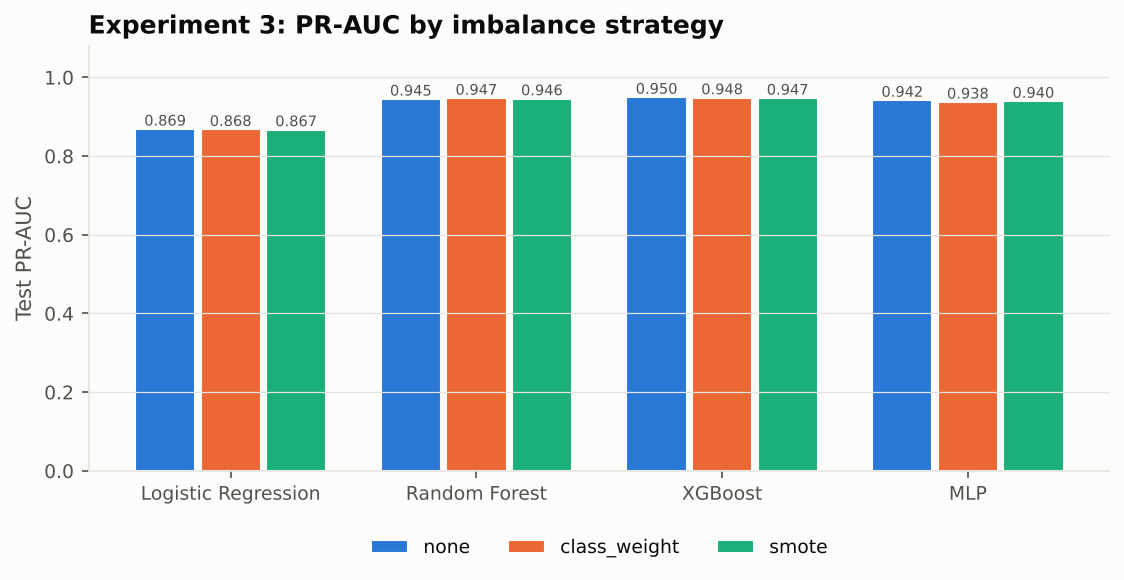

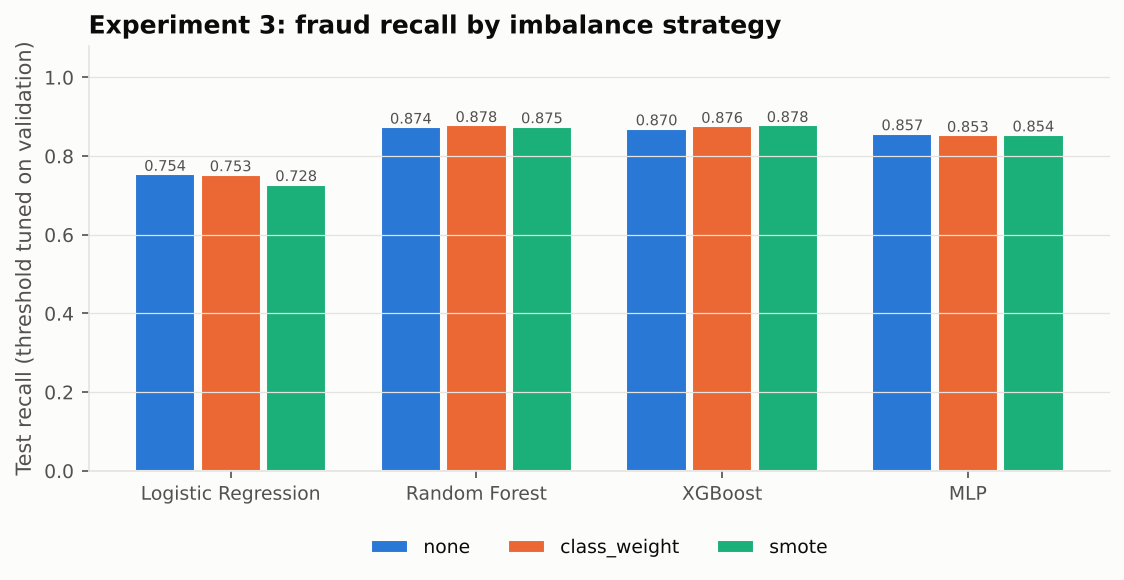

In [7]:
show('12_exp3_imbalance_prauc'); show('12_exp3_imbalance_recall')

## 5. Experiment 4 — do user-history features help?

,model,setting,val_pr_auc,pr_auc,recall,precision,f1
0,Logistic Regression,T2_behavioural,0.8456,0.8678,0.7529,0.8947,0.8177
1,Random Forest,T2_behavioural,0.9337,0.9472,0.8780,0.9802,0.9263
2,XGBoost,T2_behavioural,0.9358,0.9484,0.8759,0.9859,0.9277
3,MLP,T2_behavioural,0.9295,0.9420,0.8571,0.9821,0.9154
4,Logistic Regression,T2H_behavioural_history,0.8480,0.8715,0.7508,0.9137,0.8243
5,Random Forest,T2H_behavioural_history,0.9310,0.9455,0.8728,0.9744,0.9208
6,XGBoost,T2H_behavioural_history,0.9360,0.9483,0.8717,0.9824,0.9238
7,MLP,T2H_behavioural_history,0.9249,0.9376,0.8509,0.9867,0.9138


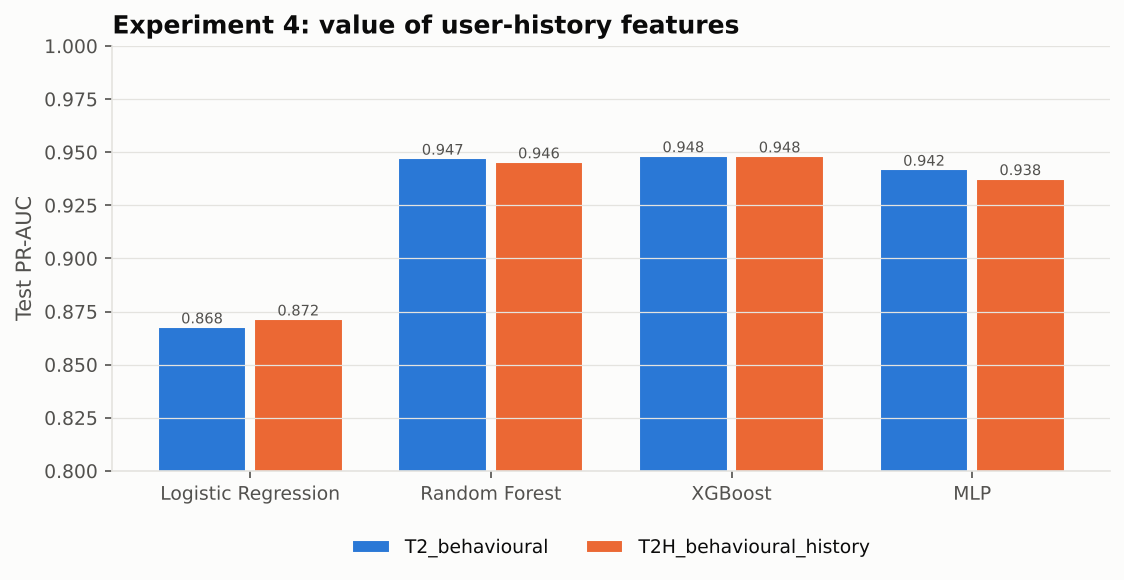

In [8]:
display(tbl('exp4_feature_engineering')[['model','setting','val_pr_auc','pr_auc','recall','precision','f1']]); show('13_exp4_features')

## 6. Experiment 5 — grouped vs random split

In [9]:
tbl('exp5_split_strategy')[['model','setting','pr_auc','roc_auc','recall','precision','f1']]

,model,setting,pr_auc,roc_auc,recall,precision,f1
0,Logistic Regression,group split (by user),0.8715,0.9183,0.7508,0.9137,0.8243
1,XGBoost,group split (by user),0.9483,0.9690,0.8717,0.9824,0.9238
2,MLP,group split (by user),0.9376,0.9600,0.8509,0.9867,0.9138
3,Logistic Regression,random row split,0.8688,0.9169,0.7349,0.9356,0.8232
4,XGBoost,random row split,0.9452,0.9664,0.8812,0.9756,0.9260
5,MLP,random row split,0.9344,0.9587,0.8339,0.9781,0.9002
